# Climate risk curves in five minutes

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/climate_risk_curves_primer.ipynb)

Every notebook in this repository answers a question with the same kind of
picture: a **climate risk curve**. This one shows how to read it, why it is
built the way it is, and how one line of code gets you a curve for any of more
than 60 hazards anywhere on Earth.

We use free, ready-made curves from **CRC Open** (Climate Risk Commons Open data)
through the open toolkit [crc-sdk](https://github.com/RiskThinking/crc-sdk), for
`CITY` below. Run it on Colab with **Runtime → Run all**; no account needed.

## Setup

In [1]:
#@title Install packages (Colab) and choose a city
import importlib.util
import os
import subprocess
import sys

IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet", "crc-sdk[geometry]>=0.11.1,<1", "plotly>=6,<7",
    ])

# Any city works: give a name and coordinates.
CITY = {"name": "Toronto, Canada", "latitude": 43.65, "longitude": -79.38}

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow as pa
import pyarrow.parquet as pq

from crc_sdk.fitting import fit_distribution
from crc_sdk.workflows import HazardDataset, curve_parameters_from_row

# Interactive charts when you run it; saved images so GitHub can show them too.
STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"

DATA = Path("data") / "primer"
DATA.mkdir(parents=True, exist_ok=True)

INK, BLUE, ORANGE, LIGHT = "#52514e", "#2a78d6", "#eb6834", "#f0efec"
FONT = dict(family="Inter, Helvetica, Arial, sans-serif", size=14)
RP_TICKS = [1, 2, 5, 10, 20, 50, 100, 200]
rp_grid = np.geomspace(1.05, 200, 300)


def curve_values(distribution, return_periods):
    """Evaluate a curve at return periods (years)."""
    return np.asarray(distribution.quantiles((1 - 1 / np.asarray(return_periods)).tolist()), dtype=float)


def layout(fig, title, **kwargs):
    fig.update_layout(title=dict(text=title, x=0.01), font=FONT, height=430,
                      margin=dict(l=70, r=30, t=70, b=60), **kwargs)
    return fig


def log_rp_axis(**kwargs):
    return dict(type="log", title="Return period (years, log scale)", tickvals=RP_TICKS, **kwargs)


def crc_open_curves(hazard, horizons):
    """CRC Open curves for one hazard at CITY, keyed by horizon."""
    plan = (
        HazardDataset.crc_open()
        .for_area((CITY["longitude"] - 0.05, CITY["latitude"] - 0.05,
                   CITY["longitude"] + 0.05, CITY["latitude"] + 0.05))
        .hazards([hazard])
        .horizons(list(horizons))
        .cache(DATA / "crc-open", mode="reuse")
    )
    city = pa.table({"asset_id": [CITY["name"]], "longitude": [CITY["longitude"]], "latitude": [CITY["latitude"]]})
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        plan.for_assets(city).return_periods([2]).write_parquet(DATA / f"city_{hazard}.parquet")
        plan.materialize(DATA / f"{hazard}.parquet")
    cell = pq.read_table(DATA / f"city_{hazard}.parquet").column("cell_index")[0].as_py()
    rows = [row for row in pq.read_table(DATA / f"{hazard}.parquet").to_pylist()
            if row["cell_index"] == cell and row["curve_kind"] != "no_data"]
    metadata = plan.resolve().catalog.hazards[hazard]
    return {row["horizon"]: curve_parameters_from_row(row).to_distribution() for row in rows}, metadata

## 1. A curve is a die for one year

Take the **wettest day of the year**. Some years it barely rains; once in a while
a storm dumps a lot. A climate risk curve lists every possible amount together
with **how often** it comes around.

"How often" is written as a **return period**: a *1-in-10-year* wettest day is
one that a year has a 10% chance of reaching or beating. Think of each year as
rolling a 10-sided die: a 1-in-10-year day is a roll of 10.

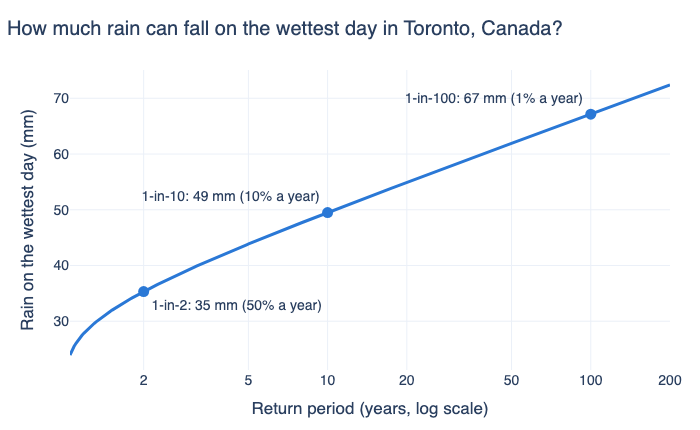

,return period (years),chance in any year,wettest day (mm)
0,2,50%,35.0
1,5,20%,44.0
2,10,10%,49.0
3,25,4%,57.0
4,50,2%,62.0
5,100,1%,67.0


In [3]:
rain, rain_meta = crc_open_curves("rx1day", [2025])
curve = rain[2025]

marks = [2, 10, 100]
fig = go.Figure()
fig.add_trace(go.Scatter(x=rp_grid, y=curve_values(curve, rp_grid), mode="lines",
                         line=dict(color=BLUE, width=3), name="CRC Open curve (2025)",
                         hovertemplate="1-in-%{x:.0f} years: %{y:.0f} mm<extra></extra>"))
for rp, value, position in zip(marks, curve_values(curve, marks), ("bottom right", "top left", "top left")):
    fig.add_trace(go.Scatter(x=[rp], y=[value], mode="markers+text", marker=dict(size=11, color=BLUE),
                             text=[f"1-in-{rp}: {value:.0f} mm ({100 / rp:g}% a year)"],
                             textposition=position, showlegend=False, hoverinfo="skip"))
layout(fig, f"How much rain can fall on the wettest day in {CITY['name']}?",
       xaxis=log_rp_axis(), yaxis_title="Rain on the wettest day (mm)", showlegend=False)
fig.show()

table = pd.DataFrame({"return period (years)": [2, 5, 10, 25, 50, 100]})
table["chance in any year"] = (100 / table["return period (years)"]).map("{:g}%".format)
table["wettest day (mm)"] = curve_values(curve, table["return period (years)"]).round(0)
table

Read it left to right: **common** days on the left, **rare** days on the right.
The further right, the bigger the number and the smaller the chance.

## 2. Thirty years of records is only thirty rolls

Why not just look at the past? Let's pretend the curve above is the true die and
**roll it for 30 years**, like a weather station with a 30-year record.

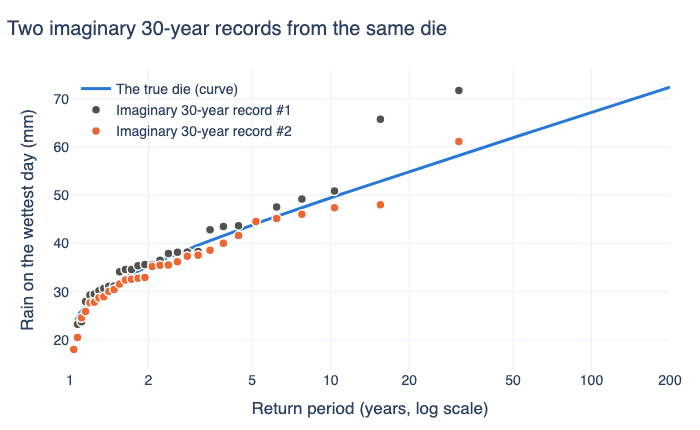

In [4]:
rng = np.random.default_rng(7)
YEARS = 30


def roll(n):
    return np.asarray(curve.quantiles(rng.uniform(0.001, 0.999, n).tolist()), dtype=float)


fig = go.Figure()
fig.add_trace(go.Scatter(x=rp_grid, y=curve_values(curve, rp_grid), mode="lines",
                         line=dict(color=BLUE, width=3), name="The true die (curve)"))
for i, color in enumerate((INK, ORANGE)):
    values = np.sort(roll(YEARS))
    plotting_rp = (YEARS + 1) / np.arange(YEARS, 0, -1)  # where each sorted year sits on the curve
    fig.add_trace(go.Scatter(x=plotting_rp, y=values, mode="markers", name=f"Imaginary 30-year record #{i + 1}",
                             marker=dict(size=9, color=color, line=dict(width=1.5, color="white"))))
layout(fig, "Two imaginary 30-year records from the same die",
       xaxis=log_rp_axis(range=[0, np.log10(200)]), yaxis_title="Rain on the wettest day (mm)",
       legend=dict(x=0.01, y=0.99, bgcolor="rgba(0,0,0,0)"))
fig.show()

Same die, different luck: the two records disagree most about the **rare days on
the right**, because 30 rolls rarely include a 1-in-100 roll. Now repeat the
experiment 200 times: each time, fit a curve to the 30 rolls (as you would with
real records) and read off its 1-in-100-year value.

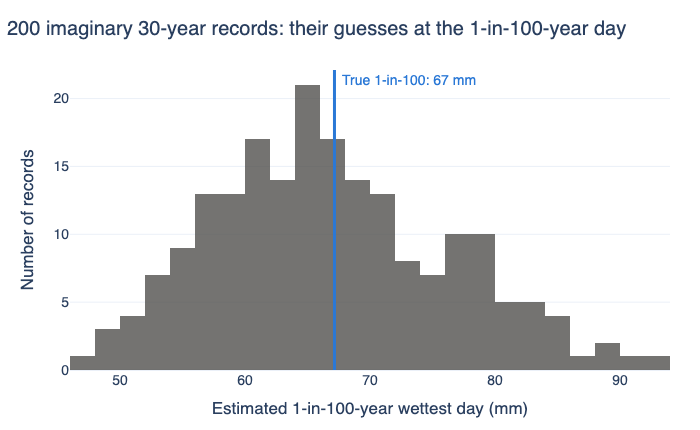

9 in 10 records guess between 53 and 83 mm (truth 67 mm).


In [5]:
true_100 = float(curve_values(curve, [100])[0])
estimates = []
for _ in range(200):
    fitted = fit_distribution(roll(YEARS), "genextreme", method="lmoments").distribution
    estimates.append(float(curve_values(fitted, [100])[0]))
estimates = np.array(estimates)
low, high = np.percentile(estimates, [5, 95])

fig = go.Figure(go.Histogram(x=estimates, nbinsx=30, marker_color=INK, opacity=0.8,
                             hovertemplate="%{x} mm: %{y} records<extra></extra>"))
fig.add_vline(x=true_100, line=dict(color=BLUE, width=3))
fig.add_annotation(x=true_100, y=1, yref="paper", text=f"True 1-in-100: {true_100:.0f} mm",
                   showarrow=False, xanchor="left", xshift=6, font=dict(color=BLUE))
layout(fig, "200 imaginary 30-year records: their guesses at the 1-in-100-year day",
       xaxis_title="Estimated 1-in-100-year wettest day (mm)", yaxis_title="Number of records", showlegend=False)
fig.show()
print(f"9 in 10 records guess between {low:.0f} and {high:.0f} mm (truth {true_100:.0f} mm).")

> 💡 **Key idea: rare events need more than one history.** A single 30-year
> record can easily be off by a lot about the once-a-century day. CRC Open curves
> are built from **many climate models and many simulated years**, which is like
> rolling the die thousands of times instead of thirty. They are still estimates,
> and rarer values remain less certain, but they are far less at the mercy of
> one lucky or unlucky stretch of weather.

## 3. Rare is not the same as "not in my lifetime"

A 1-in-100-year day sounds remote. But a building, a mortgage or a career lasts
decades, and each year is a fresh roll. The chance of **at least one** such day
in `N` years is `1 − (1 − 1/RP)^N`:

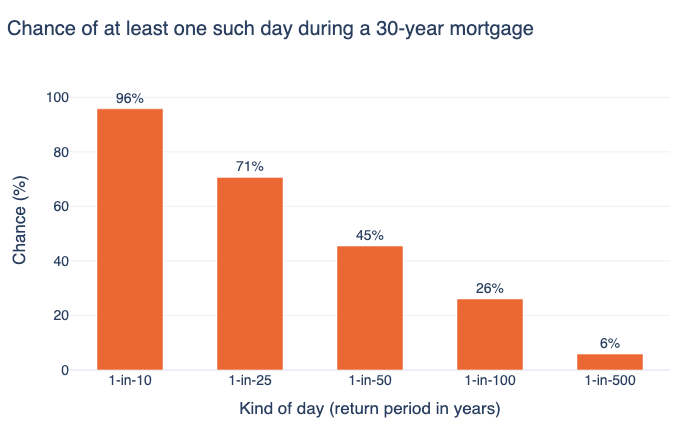

In [6]:
SPAN = 30
rps = [10, 25, 50, 100, 500]
chance = [100 * (1 - (1 - 1 / rp) ** SPAN) for rp in rps]
fig = go.Figure(go.Bar(
    x=[f"1-in-{rp}" for rp in rps], y=chance, marker_color=ORANGE, width=0.55,
    text=[f"{c:.0f}%" for c in chance], textposition="outside", cliponaxis=False,
    hovertemplate="%{x}-year day: %{y:.0f}% chance in 30 years<extra></extra>",
))
layout(fig, f"Chance of at least one such day during a {SPAN}-year mortgage",
       xaxis_title="Kind of day (return period in years)",
       yaxis=dict(title="Chance (%)", range=[0, 110]), showlegend=False)
fig.show()

More than a **1-in-4 chance** of at least one 1-in-100-year day over a 30-year
mortgage. That's why the rare end of the curve matters.

## 4. One recipe, more than 60 hazards

Every CRC curve has the same format, with its units and meaning attached, so the
code that read the rain curve works for heat, wind, wildfire weather or drought.
Below, the same function reads six hazards for `CITY`, comparing the 1-in-10-year
value early in the century with later (each averaged over three horizons, because
single horizons wobble).

In [7]:
HAZARDS = ["tx_max", "rx1day", "rx5day", "wind_max_daily_max", "fwi", "hot_days"]
EARLY, LATE = (2025, 2030, 2035), (2070, 2075, 2080)


def one_in_ten(curves, horizons):
    return float(np.mean([curve_values(curves[h], [10])[0] for h in horizons if h in curves]))


rows = []
for hazard in HAZARDS:
    curves, meta = crc_open_curves(hazard, EARLY + LATE)
    early, late = one_in_ten(curves, EARLY), one_in_ten(curves, LATE)
    unit = meta.unit
    if unit == "K":  # show temperatures in °C
        early, late, unit = early - 273.15, late - 273.15, "°C"
    rows.append({"hazard": hazard, "what it measures": meta.value_semantics, "unit": unit,
                 "1-in-10, 2025–2035": round(early, 1), "1-in-10, 2070–2080": round(late, 1),
                 "change": f"{late - early:+.1f}"})
summary = pd.DataFrame(rows)
summary

,hazard,what it measures,unit,"1-in-10, 2025–2035","1-in-10, 2070–2080",change
0,tx_max,annual maximum daily maximum temperature,°C,35.5,39.6,+4.2
1,rx1day,annual maximum one-day precipitation,mm/day,49.3,57.7,+8.3
2,rx5day,annual maximum five-day precipitation,mm,83.8,96.6,+12.8
3,wind_max_daily_max,annual maximum daily maximum wind speed,m/s,16.7,17.0,+0.3
4,fwi,annual maximum Fire Weather Index,dimensionless,22.2,27.9,+5.7
5,hot_days,annual count of hot days,days,7.1,34.8,+27.8


The same few lines work for every hazard: choose the area, the hazards and the
years, then read the curves. The full list of 63 hazards, from heat stress to drought
indices to coastal flooding, is in the
[CRC Open guide](https://github.com/RiskThinking/crc-sdk/blob/main/docs/sources/crc-open.md).

## Where next

Each question below repeats this pattern with a free outside source (A), CRC
Open (B) and Riskthinking.AI's Climate Digital Twin, CDT (C):

| Question | Notebook |
|---|---|
| How hot will the hottest day get? | [how_hot_will_it_get.ipynb](how_hot_will_it_get.ipynb) |
| How hard will it rain? | [how_hard_will_it_rain.ipynb](how_hard_will_it_rain.ipynb) |
| Which of my sites are most at risk? | [which_sites_are_most_at_risk.ipynb](which_sites_are_most_at_risk.ipynb) |

CRC Open's public release covers one high-emissions future (SSP5-8.5). Other
emissions futures are available: [contact sales](mailto:sales@riskthinking.ai).
For every future, a historical baseline and financial impact on buildings,
companies and portfolios, try [CDT Express](https://velo.riskthinking.ai/cdt-express).

*Data: CRC Open by Riskthinking.AI (CC BY-NC 4.0).*